# Task 2 - 02 Data Cleaning, Splitting and Augmentation

## Objective
Turn the raw images into clean, leak-free, ready-to-train batches:
cleaning -> resize & cache -> stratified split -> leakage check -> transforms (augmentation + normalization) -> DataLoaders.

## Short theory
* **Cleaning** removes samples that would harm training (corrupt, tiny, duplicates, extreme outliers).
* **Resize & cache (transformation / scaling)** - raw phone photos are huge (millions of pixels). We shrink every image *once* to a short side of 256 px (aspect ratio kept, EXIF rotation fixed) and store small JPEGs, so each training epoch reads small files instead of decoding giant ones.
* **Stratified split** keeps the class proportions equal in train / validation / test. *Train* = learn, *validation* = tune/early-stop, *test* = final unbiased score (touched only once, in notebook 04).
* **Data leakage** = the same (or almost the same) image in two splits; it makes test accuracy look better than it is.
* **Augmentation** creates new random variants of training images (flip, rotation, zoom, colour jitter, noise) so the model sees more variety and overfits less. It is applied to *training data only*.
* **Normalization** rescales pixels to the statistics the pretrained network expects (ImageNet mean/std).

In [1]:
# --- Setup: find the project root (the folder that contains "src") so imports work ---
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.task2 import config

warnings.filterwarnings("ignore", category=FutureWarning)
config.ensure_out_dir()
print("Project root :", ROOT.name)
print("Data folder  :", config.DATA_DIR)
print("Output folder:", config.OUT_DIR)

import torch
from src.task2 import data_utils, dataset, transforms, viz

Project root : FCVG101_Coursework
Data folder  : C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\data\raw
Output folder: C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\outputs


## Step 1 - Ingestion + quality analysis
Same as in the EDA: find all images and measure them (size, mode, brightness, MD5 hash).

In [2]:
df = data_utils.discover_dataset(config.DATA_DIR)
stats = data_utils.analyse_images(df)
print("Images found:", len(stats))

Images found: 1200


## Step 2 - Cleaning
**What:** `clean_dataset` drops (1) corrupt files, (2) images smaller than `config.MIN_IMAGE_SIZE`, (3) almost black/white outliers, (4) duplicates (same MD5; if the same file appears under two different classes, all copies are dropped because the label is ambiguous). Grayscale images are *kept* and converted to 3-channel RGB when loaded.
**Why:** every removal is logged in a report so the cleaning is transparent and reproducible.

In [3]:
clean, report = data_utils.clean_dataset(stats)
print(f"Before: {report['n_input']}   After: {report['n_output']}")
print("Removed by reason:", report["removed_by_reason"] or "nothing removed")
print("Grayscale images kept (converted to RGB later):", report["n_grayscale_kept"])
print("Imbalance ratio after cleaning:", report["imbalance_ratio_after"])
pd.DataFrame({"before": report["class_counts_before"], "after": report["class_counts_after"]})

Before: 1200   After: 1193
Removed by reason: {'duplicate': 7}
Grayscale images kept (converted to RGB later): 0
Imbalance ratio after cleaning: 1.036


,before,after
fresh_apple,200,200
fresh_banana,200,200
fresh_orange,200,193
rotten_apple,200,200
rotten_banana,200,200
rotten_orange,200,200


## Step 3 - Resize & cache (transformation / scaling)
**What:** `cache_images` writes a small copy of every cleaned image into `Task2/data/processed/<class>/`: EXIF rotation fixed -> RGB -> short side shrunk to `config.CACHE_SHORT_SIDE` = 256 px (aspect ratio kept, never enlarged) -> JPEG quality 95. Existing files are skipped, so re-running is cheap.
**Why:** (1) speed - training reads 256 px files instead of 10-megapixel photos; (2) the evaluation pipeline needs a 256 px short side anyway (Resize 256 -> CenterCrop 224); (3) the cached files are what the model sees, so raw and processed paths are both kept in `splits.csv`.

In [4]:
clean = data_utils.cache_images(clean)
raw_mb = sum(Path(p).stat().st_size for p in clean["path"]) / 1024 ** 2
cached_mb = sum(Path(p).stat().st_size for p in clean["processed_path"]) / 1024 ** 2
print(f"Raw images      : {raw_mb:,.0f} MB")
print(f"Processed images: {cached_mb:,.0f} MB  ({raw_mb / cached_mb:.0f}x smaller)")
shapes = pd.Series([Image.open(p).size for p in clean["processed_path"].head(300)])
print("Example processed sizes (w, h):", shapes.head(5).tolist(), "-> short side always <= 256")

Raw images      : 1,134 MB
Processed images: 24 MB  (47x smaller)


Example processed sizes (w, h): [(341, 256), (280, 256), (256, 311), (308, 256), (278, 256)] -> short side always <= 256


## Step 4 - Stratified train / validation / test split
**What:** `make_splits` splits 70 / 15 / 15 (or uses the dataset's own `test` folder if there is one). Both cuts are *stratified* by class and seeded (`config.SEED`). Photos that are near-duplicates of each other (perceptual hash, see Step 5; at most `config.NEAR_DUP_MAX_DISTANCE` = 10 of 256 hash bits differ) are kept together in the same split.
**Why:** reproducible class proportions in every split, and no (near-)identical photo on both sides of the train/test border. The result is saved as `splits.csv` (raw path + processed path) plus `class_names.json`.

{'train': 870, 'val': 170, 'test': 153}


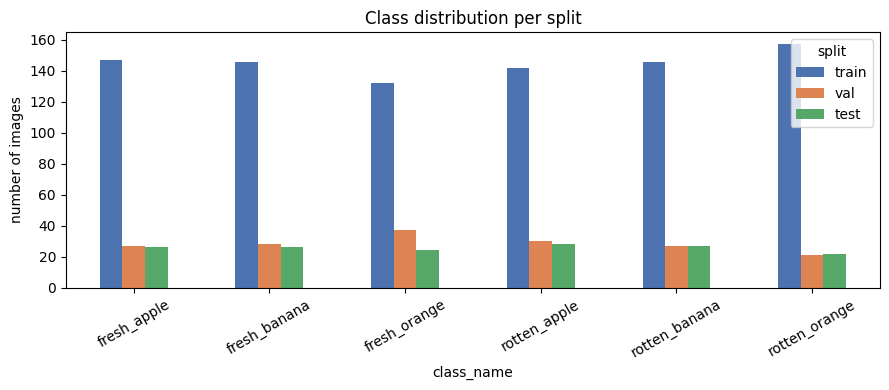

split,test,train,val
class_name,,,
fresh_apple,26,147,27
fresh_banana,26,146,28
fresh_orange,24,132,37
rotten_apple,28,142,30
rotten_banana,27,146,27
rotten_orange,22,157,21


In [5]:
splits = data_utils.make_splits(clean)
print(splits["split"].value_counts().to_dict())
viz.plot_split_distribution(splits, save_path=config.OUT_DIR / "split_distribution.png")
plt.show()
pd.crosstab(splits["class_name"], splits["split"])

## Step 5 - Leakage check (exact and near-duplicate)
**What:** (a) count images that appear in more than one split by file path and by MD5 content hash; (b) look for *near-duplicates*: photos of the same fruit taken a moment apart have almost the same 16x16 "average hash" (`config.NEAR_DUP_MAX_DISTANCE` = at most 10 of 256 bits differ; a deliberately generous limit, because grouping two different photos by mistake is harmless while missing a duplicate leaks). For comparison we also count how many such pairs a plain random split (without grouping) would have put across splits, and how many *looser* matches (<= 15 bits) remain.
**Why:** all exact and near-duplicate numbers for our split must be 0, otherwise the test score is not trustworthy. A hash is only a coarse screen: the data contains several photos of the same fruit, and photos taken from a different angle are NOT caught. Looser matches (<= 15 bits) are therefore expected to remain; notebook 04 inspects them.

In [6]:
leakage = data_utils.check_leakage(splits)
near_pairs = data_utils.find_near_duplicates(splits)
leakage["near-duplicate pairs across splits (hash distance <= %d)" % config.NEAR_DUP_MAX_DISTANCE] = len(near_pairs)
print(leakage)
assert all(v == 0 for v in leakage.values()), "Data leakage detected!"
print("No exact or near-duplicate leakage between splits.")

plain = data_utils.make_splits(clean, save=False, near_dup_distance=None)       # naive random split
groups = data_utils.near_duplicate_groups(clean)
rows = {"grouped split (used)": splits, "plain random split": plain}
leak_table = pd.DataFrame({name: {f"pairs across splits, <= {t} bits": len(data_utils.find_near_duplicates(df_, t))
                                  for t in (5, 10, 15)} for name, df_ in rows.items()})
n_plain = int(leak_table.loc[f"pairs across splits, <= {config.NEAR_DUP_MAX_DISTANCE} bits", "plain random split"])
print(f"\n{int((groups.map(groups.value_counts()) > 1).sum())} images belong to a near-duplicate group of size >= 2 (largest group: {int(groups.value_counts().max())}).")
leak_table

{'path: train & val': 0, 'path: train & test': 0, 'path: val & test': 0, 'md5: train & val': 0, 'md5: train & test': 0, 'md5: val & test': 0, 'near-duplicate pairs across splits (hash distance <= 10)': 0}
No exact or near-duplicate leakage between splits.

181 images belong to a near-duplicate group of size >= 2 (largest group: 24).


,grouped split (used),plain random split
"pairs across splits, <= 5 bits",0,4
"pairs across splits, <= 10 bits",0,72
"pairs across splits, <= 15 bits",289,479


## Step 6 - Transforms (what the model actually sees)
**Training pipeline** (random, different every epoch): RandomResizedCrop -> HorizontalFlip -> Rotation -> ColorJitter -> ToTensor -> Gaussian noise -> Normalize.
**Evaluation pipeline** (deterministic): Resize -> CenterCrop -> ToTensor -> Normalize.
Note: the hue jitter is tiny on purpose, because colour is the main signal for fresh vs rotten.

In [7]:
train_tf = transforms.get_train_transforms()
eval_tf = transforms.get_eval_transforms()
print("TRAIN:", train_tf, sep="\n")
print("\nEVAL:", eval_tf, sep="\n")

TRAIN:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.8, 1.2), hue=(-0.02, 0.02))
    ToTensor()
    AddGaussianNoise(std=0.03, p=0.3)
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

EVAL:
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


## Step 7 - Augmentation visualisation
**What:** the *same* training image passed several times through the random training pipeline. A second figure shows noise injection with increasing strength.
**Why:** to check that the augmentations look realistic (a rotten banana must still look like a rotten banana).

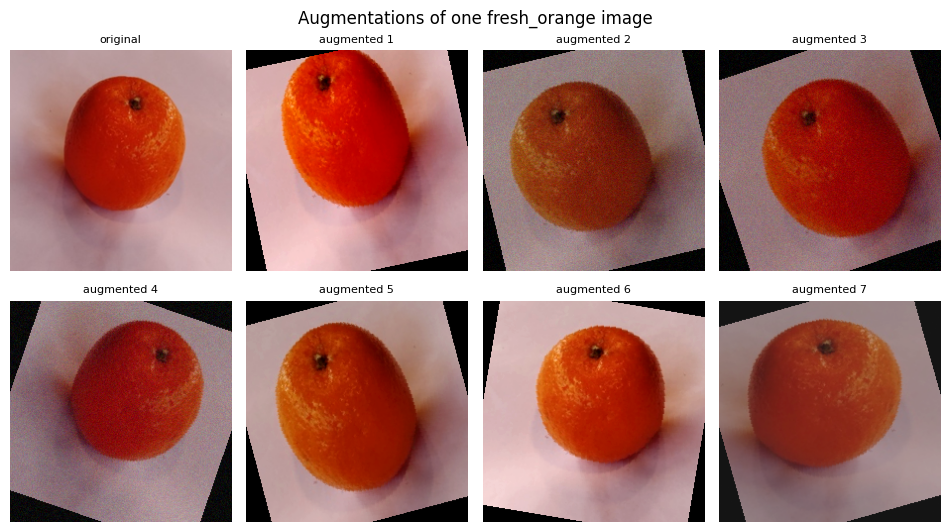

In [8]:
torch.manual_seed(config.SEED)
example = splits[splits["split"] == "train"].sample(1, random_state=config.SEED).iloc[0]
original = Image.open(example["processed_path"]).convert("RGB")   # the cached 256 px copy

images, titles = [original.resize((224, 224))], ["original"]
for i in range(7):
    augmented = transforms.denormalize(train_tf(original))          # tensor -> 0..1 for display
    images.append(augmented.permute(1, 2, 0).numpy())
    titles.append(f"augmented {i + 1}")
viz.show_image_grid(images, titles, ncols=4, save_path=config.OUT_DIR / "aug_examples.png")
plt.suptitle(f"Augmentations of one {example['class_name']} image", y=1.02)
plt.show()

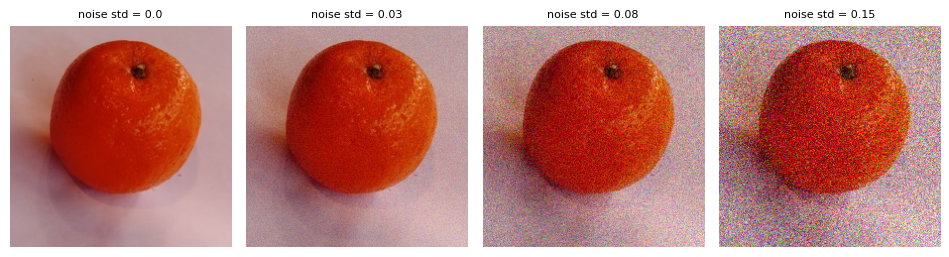

In [9]:
base = transforms.get_eval_transforms()(original)                    # normalized tensor
noise_images, noise_titles = [], []
for std in [0.0, 0.03, 0.08, 0.15]:
    noisy = transforms.AddGaussianNoise(std=std, p=1.0)(transforms.denormalize(base))
    noise_images.append(noisy.permute(1, 2, 0).numpy())
    noise_titles.append(f"noise std = {std}")
viz.show_image_grid(noise_images, noise_titles, ncols=4, save_path=config.OUT_DIR / "aug_noise.png")
plt.show()

## Step 8 - DataLoader sanity check
**What:** build the three DataLoaders, pull one batch, check shape and value range, and show the de-normalized images with their labels. Also compute class weights for the loss.
**Why:** catches wrong shapes, wrong labels or broken normalization *before* spending time on training. Normalized values should lie roughly in [-2.2, 2.7] (0 = the ImageNet average colour).

Batch of images: (32, 3, 224, 224) dtype: torch.float32
Batch of labels: (32,) [1, 4, 0, 0, 3, 1, 5, 4]
Pixel range: min -2.12, max 2.64, mean 0.38, std 1.29


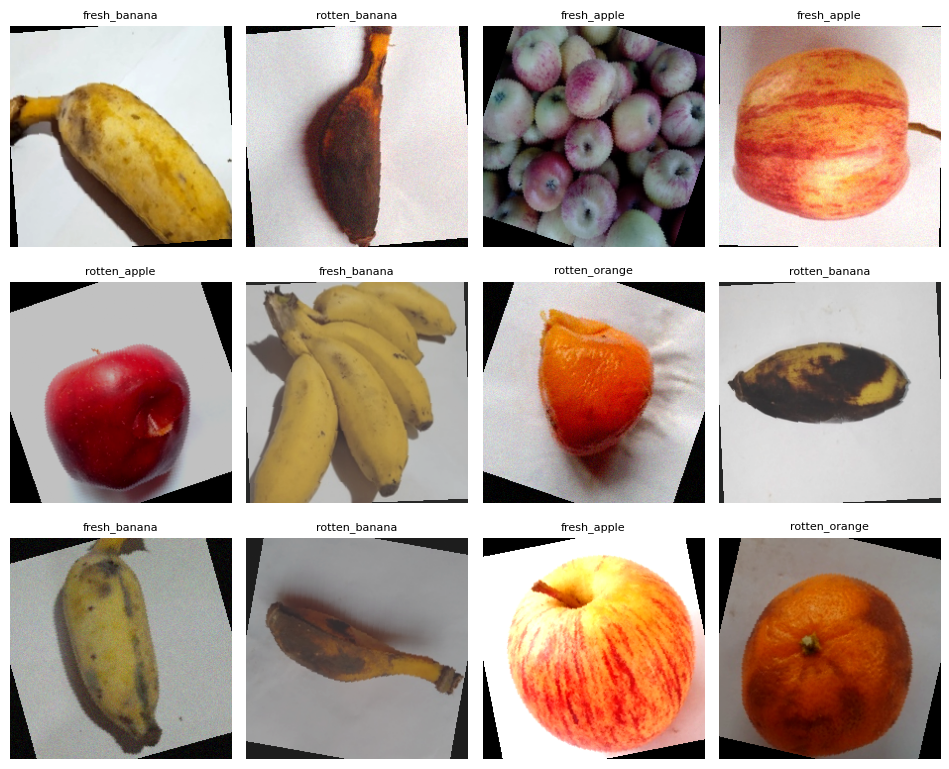

In [10]:
loaders = dataset.make_dataloaders(splits)
images, labels = next(iter(loaders["train"]))
print("Batch of images:", tuple(images.shape), "dtype:", images.dtype)
print("Batch of labels:", tuple(labels.shape), labels[:8].tolist())
print(f"Pixel range: min {images.min():.2f}, max {images.max():.2f}, mean {images.mean():.2f}, std {images.std():.2f}")

class_names = data_utils.class_names_from_df(splits)
shown = transforms.denormalize(images[:12]).permute(0, 2, 3, 1).numpy()
viz.show_image_grid(shown, [class_names[int(i)] for i in labels[:12]], ncols=4,
                    save_path=config.OUT_DIR / "dataloader_batch.png")
plt.show()

In [11]:
train_df = splits[splits["split"] == "train"]
weights = dataset.compute_class_weights(train_df, len(class_names))
pd.DataFrame({"train_images": train_df["class_name"].value_counts().reindex(class_names),
              "loss_weight": weights.numpy().round(3)})

,train_images,loss_weight
class_name,,
fresh_apple,147,0.986
fresh_banana,146,0.993
fresh_orange,132,1.098
rotten_apple,142,1.021
rotten_banana,146,0.993
rotten_orange,157,0.924


## Step 9 - Save the preprocessing summary

In [12]:
summary = {
    "cleaning_report": {k: v for k, v in report.items() if k != "removed_files"},
    "removed_files_first_50": report["removed_files"],
    "split_sizes": splits["split"].value_counts().to_dict(),
    "used_provided_test_folder": bool((splits["source_split"] == "test").any()),
    "leakage_check": leakage,
    "plain_random_split_near_duplicate_pairs": n_plain,
    "images_in_near_duplicate_groups": int((groups.map(groups.value_counts()) > 1).sum()),
    "largest_near_duplicate_group": int(groups.value_counts().max()),
    "near_duplicate_pairs_by_threshold": leak_table.to_dict(),
    "near_dup_max_hash_distance": config.NEAR_DUP_MAX_DISTANCE,
    "resize_cache": {"short_side": config.CACHE_SHORT_SIDE, "jpeg_quality": config.CACHE_JPEG_QUALITY,
                     "raw_mb": round(raw_mb, 1), "processed_mb": round(cached_mb, 1)},
    "class_names": class_names,
    "class_weights": dict(zip(class_names, [round(float(w), 4) for w in weights])),
    "train_transforms": str(train_tf),
    "eval_transforms": str(eval_tf),
    "batch_shape": list(images.shape),
}
(config.OUT_DIR / "preprocess_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved:", sorted(p.name for p in config.OUT_DIR.glob("*") if p.suffix in (".csv", ".json")))

Saved: ['class_names.json', 'eda_summary.json', 'preprocess_summary.json', 'splits.csv']


## Summary / Observations
* **Cleaning:** 1,200 -> **1,193** images. Removed 7 exact duplicates (all `fresh_orange`, 200 -> 193); no corrupt, too-small, outlier-brightness or grayscale images. Imbalance ratio after cleaning 1.04.
* **Resize & cache (transformation/scaling):** every image was EXIF-corrected, converted to RGB and shrunk to a 256 px short side (JPEG quality 95, aspect ratio kept): **1,134 MB -> 24 MB (47x smaller)**. One training epoch now takes about 7 s instead of decoding 10-megapixel photos each time. Raw and processed paths are both stored in `splits.csv`.
* **Split:** train **870** / validation **170** / test **153**, stratified by class, seed 42. This is 73 % / 14 % / 13 % rather than exactly 70/15/15, because near-duplicate photos are kept together in one split (181 images belong to a near-duplicate group, largest group 24). Class counts per split: test 22-28 per class.
* **Leakage check:** 0 shared files (path), 0 shared content hashes (MD5) and 0 near-duplicate pairs (hash distance <= 10 of 256 bits) between splits. A plain random split would have put **72** such pairs (4 of them <= 5 bits) across train/val/test. A looser threshold (<= 15 bits) still finds 289 pairs: these are mostly merely similar-looking fruit on the same plain background, but some are probably other photos of the same fruit, so a small residual optimism in the test score cannot be excluded (see notebook 04).
* **Class balance:** loss weights range 0.92-1.10, i.e. the data is balanced and the class weighting has almost no effect.
* **Augmentation:** crop/zoom (scale 0.7-1.0), horizontal flip, rotation +-20 deg, colour jitter (brightness/contrast 0.3, saturation 0.2, hue only 0.02) and Gaussian noise (std 0.03, p = 0.3). The examples in `aug_examples.png` still look like realistic fruit photos; rotation leaves black corners, which is acceptable. The noise figure shows that std 0.15 is already very strong, so 0.03 is a mild setting.
* **Normalization / DataLoader:** ImageNet mean/std; batch tensor (32, 3, 224, 224), values from -2.12 to 2.64 (mean 0.38, std 1.29 for this augmented batch).
* **Next step:** notebook 03 trains a ResNet18 on these loaders.